In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, accuracy_score, classification_report

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

In [3]:
df = pd.read_csv(
    "urlset.csv",
    encoding="latin1",
    low_memory=False,
    on_bad_lines="skip"
)


print("Dataset shape:", df.shape)
df.head()

Dataset shape: (96005, 14)


,domain,ranking,mld_res,mld.ps_res,card_rem,ratio_Rrem,ratio_Arem,jaccard_RR,jaccard_RA,jaccard_AR,jaccard_AA,jaccard_ARrd,jaccard_ARrem,label
0,nobell.it/70ffb52d079109dca5664cce6f317373782/...,10000000,1.0,0.0,18.0,107.611111,107.277778,0.0,0.0,0.0,0.0,0.8,0.795729,1.0
1,www.dghjdgf.com/paypal.co.uk/cycgi-bin/webscrc...,10000000,0.0,0.0,11.0,150.636364,152.272727,0.0,0.0,0.0,0.0,0,0.768577,1.0
2,serviciosbys.com/paypal.cgi.bin.get-into.herf....,10000000,0.0,0.0,14.0,73.500000,72.642857,0.0,0.0,0.0,0.0,0,0.726582,1.0
3,mail.printakid.com/www.online.americanexpress....,10000000,0.0,0.0,6.0,562.000000,590.666667,0.0,0.0,0.0,0.0,0,0.85964,1.0
4,thewhiskeydregs.com/wp-content/themes/widescre...,10000000,0.0,0.0,8.0,29.000000,24.125000,0.0,0.0,0.0,0.0,0,0.748971,1.0


In [4]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96005 entries, 0 to 96004
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   domain         96005 non-null  object 
 1   ranking        95953 non-null  object 
 2   mld_res        95935 non-null  object 
 3   mld.ps_res     95924 non-null  object 
 4   card_rem       95923 non-null  float64
 5   ratio_Rrem     95923 non-null  float64
 6   ratio_Arem     95923 non-null  float64
 7   jaccard_RR     95922 non-null  float64
 8   jaccard_RA     95921 non-null  float64
 9   jaccard_AR     95920 non-null  float64
 10  jaccard_AA     95919 non-null  float64
 11  jaccard_ARrd   95919 non-null  object 
 12  jaccard_ARrem  95917 non-null  object 
 13  label          95913 non-null  float64
dtypes: float64(8), object(6)
memory usage: 10.3+ MB
None


In [5]:
print(df.isnull().sum())

domain            0
ranking          52
mld_res          70
mld.ps_res       81
card_rem         82
ratio_Rrem       82
ratio_Arem       82
jaccard_RR       83
jaccard_RA       84
jaccard_AR       85
jaccard_AA       86
jaccard_ARrd     86
jaccard_ARrem    88
label            92
dtype: int64


In [6]:
print(df["label"].value_counts())

label
0.0    48009
1.0    47904
Name: count, dtype: int64


In [7]:
features = [
    "ranking",
    "mld_res",
    "mld.ps_res",
    "card_rem",
    "ratio_Rrem",
    "ratio_Arem",
    "jaccard_RR",
    "jaccard_RA",
    "jaccard_AR",
    "jaccard_AA",
    "jaccard_ARrd",
    "jaccard_ARrem"
]

X = df[features]
y = df["label"]

In [8]:
X = X.apply(pd.to_numeric, errors="coerce")
y = pd.to_numeric(y, errors="coerce")


In [9]:
data = pd.concat([X, y], axis=1)

data = data.dropna(subset=["label"])

X = data[features]
y = data["label"].astype(int)

X = X.fillna(X.median())

print("Final dataset shape:", X.shape)

Final dataset shape: (95913, 12)


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 76730
Testing samples: 19183


In [11]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


In [12]:
model_1 = Sequential()

model_1.add(Dense(32, activation="relu", input_shape=(X_train.shape[1],)))
model_1.add(Dense(16, activation="relu"))
model_1.add(Dense(1, activation="sigmoid"))

model_1.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model_1.summary()

C:\Users\admin\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 961 (3.75 KB)

 Trainable params: 961 (3.75 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
history_1 = model_1.fit(
    X_train,
    y_train,
    validation_split=0.20,
    epochs=20,
    batch_size=32,
    verbose=1
)

Epoch 1/20
1919/1919 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.7979 - loss: 0.4127 - val_accuracy: 0.8452 - val_loss: 0.3490
Epoch 2/20
1919/1919 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8474 - loss: 0.3439 - val_accuracy: 0.8496 - val_loss: 0.3430
Epoch 3/20
1919/1919 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8489 - loss: 0.3365 - val_accuracy: 0.8506 - val_loss: 0.3355
Epoch 4/20
1919/1919 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8512 - loss: 0.3316 - val_accuracy: 0.8538 - val_loss: 0.3305
Epoch 5/20
1919/1919 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8526 - loss: 0.3292 - val_accuracy: 0.8559 - val_loss: 0.3251
Epoch 6/20
1919/1919 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8568 - loss: 0.3189 - val_accuracy: 0.8574 - val_loss: 0.3187
Epoch 7/20
1919/1919 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.8593 - loss: 0.3142 - val_accuracy: 0.8594 - val_loss: 0.3142
Epoch 8/20
1919/1919 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8657 - loss: 0.3051 -

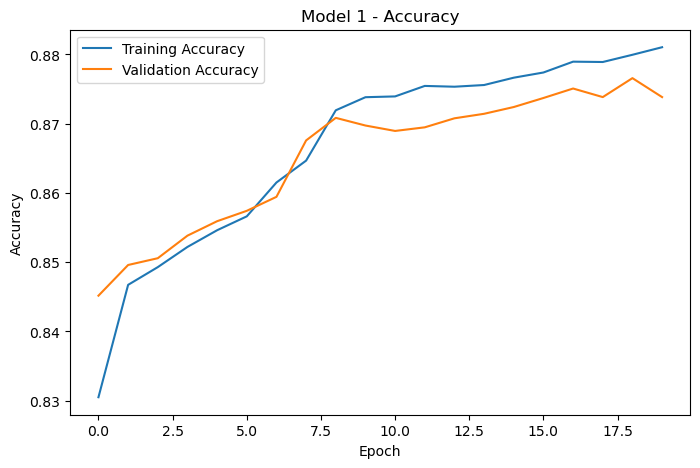

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(history_1.history["accuracy"], label="Training Accuracy")
plt.plot(history_1.history["val_accuracy"], label="Validation Accuracy")

plt.title("Model 1 - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

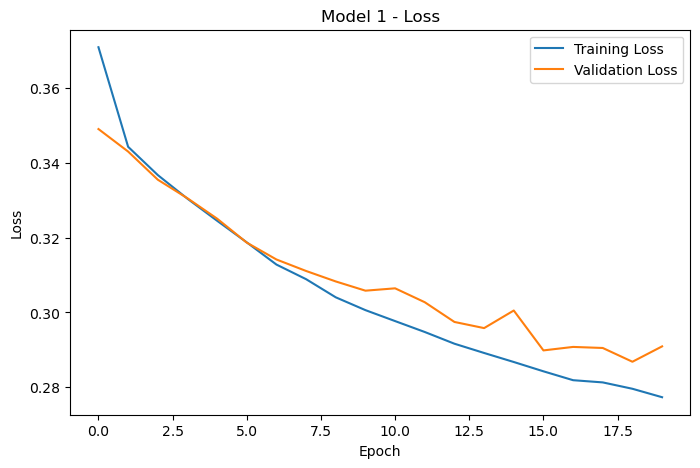

In [15]:
plt.figure(figsize=(8, 5))

plt.plot(history_1.history["loss"], label="Training Loss")
plt.plot(history_1.history["val_loss"], label="Validation Loss")

plt.title("Model 1 - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

In [16]:
probability_1 = model_1.predict(X_test)

prediction_1 = (probability_1 >= 0.5).astype(int).flatten()

600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [17]:
accuracy_1 = accuracy_score(y_test, prediction_1)
precision_1 = precision_score(y_test, prediction_1)
recall_1 = recall_score(y_test, prediction_1)
f1_1 = f1_score(y_test, prediction_1)

print("Model 1 Results")
print("Accuracy :", accuracy_1)
print("Precision:", precision_1)
print("Recall   :", recall_1)
print("F1-Score :", f1_1)

Model 1 Results
Accuracy : 0.8766094979930147
Precision: 0.8807261980156217
Recall   : 0.8708903037261246
F1-Score : 0.875780635003936


In [18]:
model_2 = Sequential()

model_2.add(Dense(64, activation="relu", input_shape=(X_train.shape[1],)))
model_2.add(Dense(32, activation="relu"))
model_2.add(Dense(1, activation="sigmoid"))

model_2.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model_2.summary()

C:\Users\admin\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,945 (11.50 KB)

 Trainable params: 2,945 (11.50 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
history_2 = model_2.fit(
    X_train,
    y_train,
    validation_split=0.20,
    epochs=20,
    batch_size=32,
    verbose=1
)

Epoch 1/20
1919/1919 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.8189 - loss: 0.3946 - val_accuracy: 0.8372 - val_loss: 0.3478
Epoch 2/20
1919/1919 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8513 - loss: 0.3324 - val_accuracy: 0.8429 - val_loss: 0.3355
Epoch 3/20
1919/1919 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8564 - loss: 0.3246 - val_accuracy: 0.8651 - val_loss: 0.3189
Epoch 4/20
1919/1919 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8649 - loss: 0.3127 - val_accuracy: 0.8691 - val_loss: 0.3037
Epoch 5/20
1919/1919 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8726 - loss: 0.3007 - val_accuracy: 0.8677 - val_loss: 0.3009
Epoch 6/20
1919/1919 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8741 - loss: 0.2926 - val_accuracy: 0.8713 - val_loss: 0.2936
Epoch 7/20
1919/1919 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8747 - loss: 0.2893 - val_accuracy: 0.8740 - val_loss: 0.2870
Epoch 8/20
1919/1919 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8781 - loss: 0.2847 -

In [20]:
probability_2 = model_2.predict(X_test)

prediction_2 = (probability_2 >= 0.5).astype(int).flatten()

600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step


In [21]:
accuracy_2 = accuracy_score(y_test, prediction_2)
precision_2 = precision_score(y_test, prediction_2)
recall_2 = recall_score(y_test, prediction_2)
f1_2 = f1_score(y_test, prediction_2)

print("Model 2 Results")
print("Accuracy :", accuracy_2)
print("Precision:", precision_2)
print("Recall   :", recall_2)
print("F1-Score :", f1_2)

Model 2 Results
Accuracy : 0.8846374393994683
Precision: 0.8970683336926062
Recall   : 0.868698465713391
F1-Score : 0.8826554960496314


In [22]:
model_3 = Sequential()

model_3.add(Dense(64, activation="relu", input_shape=(X_train.shape[1],)))
model_3.add(Dense(32, activation="relu"))
model_3.add(Dense(1, activation="sigmoid"))

model_3.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model_3.summary()

C:\Users\admin\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 64)             │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,945 (11.50 KB)

 Trainable params: 2,945 (11.50 KB)

 Non-trainable params: 0 (0.00 B)

In [23]:
history_3 = model_3.fit(
    X_train,
    y_train,
    validation_split=0.20,
    epochs=20,
    batch_size=32,
    verbose=1
)

Epoch 1/20
1919/1919 ━━━━━━━━━━━━━━━━━━━━ 14s 4ms/step - accuracy: 0.7778 - loss: 0.5064 - val_accuracy: 0.8372 - val_loss: 0.3694
Epoch 2/20
1919/1919 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8393 - loss: 0.3640 - val_accuracy: 0.8431 - val_loss: 0.3575
Epoch 3/20
1919/1919 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8447 - loss: 0.3568 - val_accuracy: 0.8425 - val_loss: 0.3520
Epoch 4/20
1919/1919 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8479 - loss: 0.3494 - val_accuracy: 0.8450 - val_loss: 0.3481
Epoch 5/20
1919/1919 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8510 - loss: 0.3419 - val_accuracy: 0.8495 - val_loss: 0.3436
Epoch 6/20
1919/1919 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8518 - loss: 0.3409 - val_accuracy: 0.8498 - val_loss: 0.3405
Epoch 7/20
1919/1919 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8519 - loss: 0.3383 - val_accuracy: 0.8507 - val_loss: 0.3386
Epoch 8/20
1919/1919 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8546 - loss: 0.3317 -

In [24]:
probability_3 = model_3.predict(X_test)

prediction_3 = (probability_3 >= 0.5).astype(int).flatten()

600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step


In [25]:
accuracy_3 = accuracy_score(y_test, prediction_3)
precision_3 = precision_score(y_test, prediction_3)
recall_3 = recall_score(y_test, prediction_3)
f1_3 = f1_score(y_test, prediction_3)

print("Model 3 Results")
print("Accuracy :", accuracy_3)
print("Precision:", precision_3)
print("Recall   :", recall_3)
print("F1-Score :", f1_3)

Model 3 Results
Accuracy : 0.8633686076213314
Precision: 0.880994088022772
Recall   : 0.8398914518317503
F1-Score : 0.8599519102324339


In [26]:
model_4 = Sequential()

model_4.add(Dense(64, activation="relu", input_shape=(X_train.shape[1],)))
model_4.add(Dense(32, activation="relu"))
model_4.add(Dense(1, activation="sigmoid"))

model_4.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history_4 = model_4.fit(
    X_train,
    y_train,
    validation_split=0.20,
    epochs=30,
    batch_size=64,
    verbose=1
)

C:\Users\admin\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/30
960/960 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.8219 - loss: 0.3947 - val_accuracy: 0.8470 - val_loss: 0.3435
Epoch 2/30
960/960 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.8475 - loss: 0.3384 - val_accuracy: 0.8504 - val_loss: 0.3293
Epoch 3/30
960/960 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.8523 - loss: 0.3262 - val_accuracy: 0.8523 - val_loss: 0.3227
Epoch 4/30
960/960 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.8631 - loss: 0.3111 - val_accuracy: 0.8632 - val_loss: 0.3178
Epoch 5/30
960/960 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.8694 - loss: 0.3023 - val_accuracy: 0.8673 - val_loss: 0.3051
Epoch 6/30
960/960 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.8742 - loss: 0.2983 - val_accuracy: 0.8688 - val_loss: 0.2998
Epoch 7/30
960/960 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.8754 - loss: 0.2925 - val_accuracy: 0.8709 - val_loss: 0.2956
Epoch 8/30
960/960 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.8776 - loss: 0.2887 - val_accuracy: 

In [27]:
probability_4 = model_4.predict(X_test)

prediction_4 = (probability_4 >= 0.5).astype(int).flatten()

600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step


In [28]:
accuracy_4 = accuracy_score(y_test, prediction_4)
precision_4 = precision_score(y_test, prediction_4)
recall_4 = recall_score(y_test, prediction_4)
f1_4 = f1_score(y_test, prediction_4)

print("Model 4 Results")
print("Accuracy :", accuracy_4)
print("Precision:", precision_4)
print("Recall   :", recall_4)
print("F1-Score :", f1_4)

Model 4 Results
Accuracy : 0.883177813689204
Precision: 0.9031195079086116
Recall   : 0.8581567686045298
F1-Score : 0.88006422263848


In [29]:
results = pd.DataFrame({
    "Model": [
        "Model 1 - Baseline",
        "Model 2 - More Neurons",
        "Model 3 - Lower Learning Rate",
        "Model 4 - Batch Size & Epochs"
    ],
    
    "Accuracy": [
        accuracy_1,
        accuracy_2,
        accuracy_3,
        accuracy_4
    ],
    
    "Precision": [
        precision_1,
        precision_2,
        precision_3,
        precision_4
    ],
    
    "Recall": [
        recall_1,
        recall_2,
        recall_3,
        recall_4
    ],
    
    "F1-Score": [
        f1_1,
        f1_2,
        f1_3,
        f1_4
    ]
})

results

,Model,Accuracy,Precision,Recall,F1-Score
0,Model 1 - Baseline,0.876609,0.880726,0.870890,0.875781
1,Model 2 - More Neurons,0.884637,0.897068,0.868698,0.882655
2,Model 3 - Lower Learning Rate,0.863369,0.880994,0.839891,0.859952
3,Model 4 - Batch Size & Epochs,0.883178,0.903120,0.858157,0.880064


In [30]:
final_prediction = prediction_4

cm = confusion_matrix(y_test, final_prediction)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[8720  882]
 [1359 8222]]


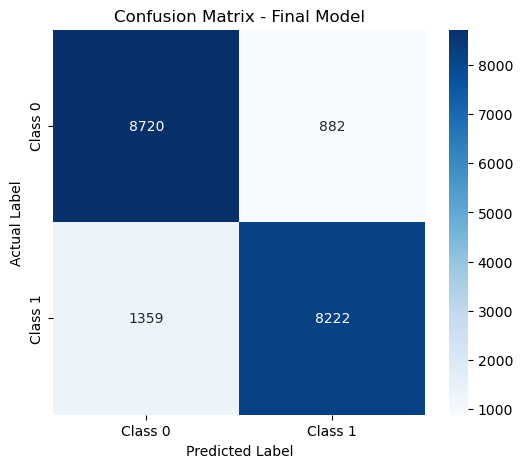

In [31]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Class 0", "Class 1"],
    yticklabels=["Class 0", "Class 1"]
)

plt.title("Confusion Matrix - Final Model")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [32]:
print("Final Model Performance")

print("Accuracy :", accuracy_score(y_test, final_prediction))
print("Precision:", precision_score(y_test, final_prediction))
print("Recall   :", recall_score(y_test, final_prediction))
print("F1-Score :", f1_score(y_test, final_prediction))

Final Model Performance
Accuracy : 0.883177813689204
Precision: 0.9031195079086116
Recall   : 0.8581567686045298
F1-Score : 0.88006422263848


In [33]:
print(classification_report(y_test, final_prediction))

              precision    recall  f1-score   support

           0       0.87      0.91      0.89      9602
           1       0.90      0.86      0.88      9581

    accuracy                           0.88     19183
   macro avg       0.88      0.88      0.88     19183
weighted avg       0.88      0.88      0.88     19183



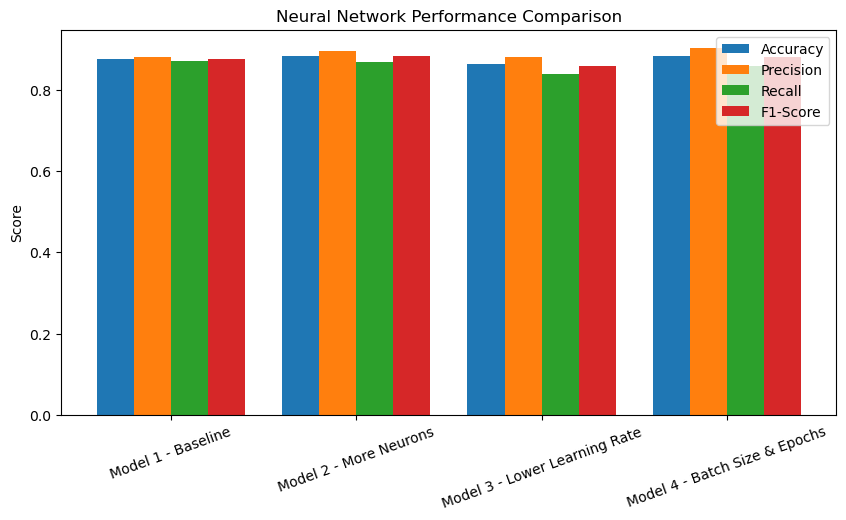

In [34]:
plt.figure(figsize=(10, 5))

x = np.arange(len(results))
width = 0.2

plt.bar(x - 1.5*width, results["Accuracy"], width, label="Accuracy")
plt.bar(x - 0.5*width, results["Precision"], width, label="Precision")
plt.bar(x + 0.5*width, results["Recall"], width, label="Recall")
plt.bar(x + 1.5*width, results["F1-Score"], width, label="F1-Score")

plt.xticks(x, results["Model"], rotation=20)
plt.ylabel("Score")
plt.title("Neural Network Performance Comparison")
plt.legend()

plt.show()

# FINAL PROJECT — Phishing URL Detection Using Neural Networks

## 1. Problem Statement
Phishing websites use deceptive URLs to trick users into visiting malicious pages and disclosing sensitive information. This project aims to develop a binary classification model that distinguishes legitimate URLs (label 0) from phishing URLs (label 1) using URL-related features. Multiple neural-network configurations are trained and compared to determine which configuration gives the best balance of accuracy, precision, recall, and F1-score.

## 2. Pipeline

**Dataset → Data inspection → EDA → Feature selection → Numeric conversion → Missing-value handling → Train/test split → Standardization → Neural-network training → Validation/training curves → Test prediction → Accuracy/Precision/Recall/F1 → Confusion matrix → Model comparison → Final model selection.**

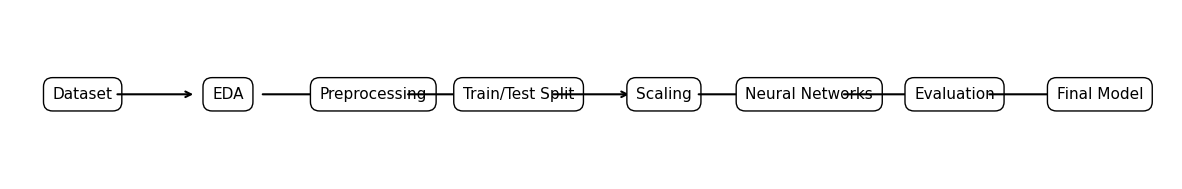

In [35]:
# Pipeline diagram
import matplotlib.pyplot as plt
steps = ["Dataset", "EDA", "Preprocessing", "Train/Test Split", "Scaling", "Neural Networks", "Evaluation", "Final Model"]
fig, ax = plt.subplots(figsize=(15, 2.2)); ax.axis("off")
for i, step in enumerate(steps):
    ax.text(i, .5, step, ha="center", va="center", fontsize=11,
            bbox=dict(boxstyle="round,pad=.6", facecolor="white", edgecolor="black"))
    if i < len(steps)-1:
        ax.annotate("", xy=(i+.78,.5), xytext=(i+.22,.5), arrowprops=dict(arrowstyle="->", lw=1.5))
ax.set_xlim(-.5, len(steps)-.5); plt.show()

## 3. Dataset

The dataset is **PhishStorm – phishing / legitimate URL dataset**, created by Samuel Marchal and colleagues. The official Aalto University record describes 96,018 URLs and identifies label 0 as legitimate and label 1 as phishing. The dataset contains the URL/domain identifier and computed features related to URL popularity and intra-URL relatedness.

**Official dataset:** https://research.aalto.fi/en/datasets/phishstorm-phishing-legitimate-url-dataset/

**Original paper:** Marchal, S., François, J., State, R., & Engel, T. (2014). *PhishStorm: Detecting Phishing With Streaming Analytics*. IEEE Transactions on Network and Service Management, 11(4), 458–471. DOI: 10.1109/TNSM.2014.2377295.

### Local-data note
The local CSV used in this project contains 96,005 rows, while the official dataset page reports 96,018. The local copy also has 92 missing labels. Rows without labels are removed before model training. This discrepancy is reported as part of data cleaning rather than ignored.

## 4. EDA and Intermediate Outputs

The W4 notebook already performs dataset inspection, missing-value analysis and label-distribution analysis. The following cells add useful final-project EDA: class distribution, feature summary, and correlation analysis.

In [36]:
# Re-load the supplied CSV if the notebook is opened independently
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df_final = pd.read_csv("urlset.csv", encoding="latin1", low_memory=False, on_bad_lines="skip")
print("Dataset shape:", df_final.shape)
print("\nMissing values:")
print(df_final.isnull().sum())
print("\nLabel distribution:")
print(df_final["label"].value_counts(dropna=False))

Dataset shape: (96005, 14)

Missing values:
domain            0
ranking          52
mld_res          70
mld.ps_res       81
card_rem         82
ratio_Rrem       82
ratio_Arem       82
jaccard_RR       83
jaccard_RA       84
jaccard_AR       85
jaccard_AA       86
jaccard_ARrd     86
jaccard_ARrem    88
label            92
dtype: int64

Label distribution:
label
0.0    48009
1.0    47904
NaN       92
Name: count, dtype: int64


                 count          mean           std  min           25%  \
ranking        95921.0  5.888234e+06  4.878506e+06  0.0  25309.000000   
mld_res        95923.0  1.047079e+02  3.228781e+04  0.0      0.000000   
mld.ps_res     95923.0  2.061530e-01  8.746421e-01  0.0      0.000000   
card_rem       95923.0  4.580498e+00  4.466073e+00  0.0      2.000000   
ratio_Rrem     95923.0  1.352552e+02  1.609889e+02  0.0     43.000000   
ratio_Arem     95923.0  1.385442e+02  1.754805e+02  0.0     39.666667   
jaccard_RR     95922.0  5.029507e-03  3.113084e-01  0.0      0.000000   
jaccard_RA     95921.0  3.787113e-03  2.481462e-02  0.0      0.000000   
jaccard_AR     95920.0  3.377884e-03  2.401052e-02  0.0      0.000000   
jaccard_AA     95919.0  3.661098e-03  2.849249e-02  0.0      0.000000   
jaccard_ARrd   95918.0  3.077625e-01  3.630940e-01  0.0      0.000000   
jaccard_ARrem  95915.0  7.036205e-01  2.042477e-01  0.0      0.675084   

                        50%           75%         

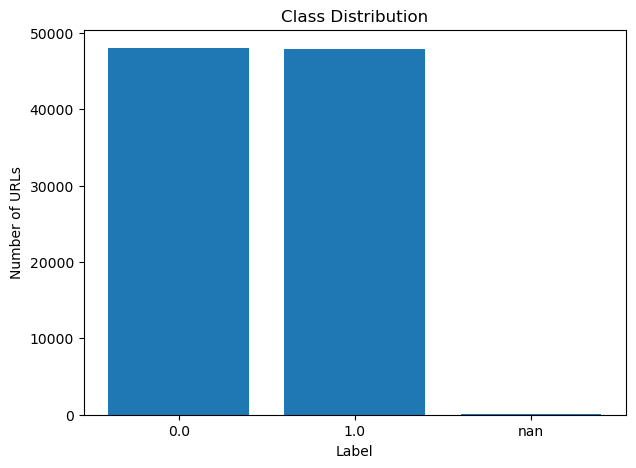

In [37]:
features_final = ["ranking","mld_res","mld.ps_res","card_rem","ratio_Rrem","ratio_Arem",
                   "jaccard_RR","jaccard_RA","jaccard_AR","jaccard_AA","jaccard_ARrd","jaccard_ARrem"]
num_final = df_final[features_final].apply(pd.to_numeric, errors="coerce")
print(num_final.describe().T)

plt.figure(figsize=(7,5))
counts = df_final["label"].value_counts(dropna=False).sort_index()
plt.bar([str(x) for x in counts.index], counts.values)
plt.xlabel("Label"); plt.ylabel("Number of URLs"); plt.title("Class Distribution"); plt.show()

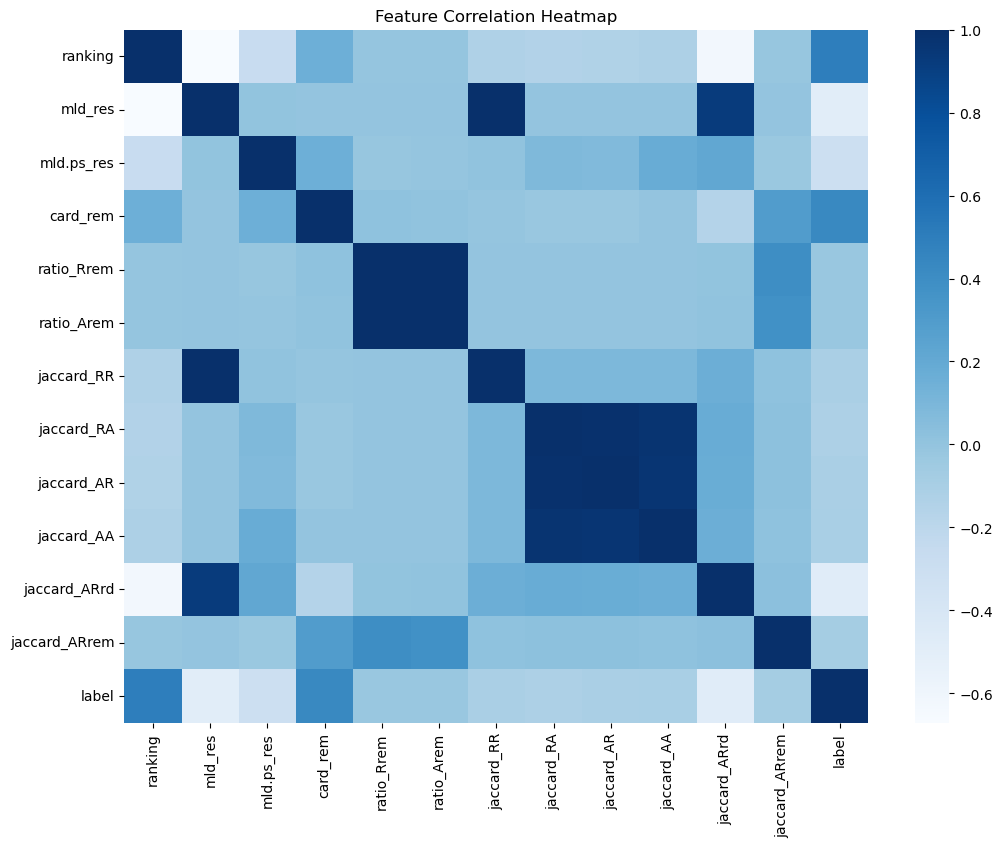

In [38]:
corr = pd.concat([num_final, pd.to_numeric(df_final["label"], errors="coerce").rename("label")], axis=1).corr()
plt.figure(figsize=(12,9)); sns.heatmap(corr, cmap="Blues", annot=False)
plt.title("Feature Correlation Heatmap"); plt.show()

## 5. Results from the Four W4 Models

The W4 experiments produced the following test-set results. These are the actual recorded outputs from the existing notebook, not newly estimated values.

In [39]:
final_results = pd.DataFrame({
    "Model": ["Model 1 - Baseline", "Model 2 - More Neurons", "Model 3 - Lower Learning Rate", "Model 4 - Batch Size & Epochs"],
    "Accuracy": [accuracy_1, accuracy_2, accuracy_3, accuracy_4],
    "Precision": [precision_1, precision_2, precision_3, precision_4],
    "Recall": [recall_1, recall_2, recall_3, recall_4],
    "F1-Score": [f1_1, f1_2, f1_3, f1_4]
})
final_results.round(4)

,Model,Accuracy,Precision,Recall,F1-Score
0,Model 1 - Baseline,0.8766,0.8807,0.8709,0.8758
1,Model 2 - More Neurons,0.8846,0.8971,0.8687,0.8827
2,Model 3 - Lower Learning Rate,0.8634,0.8810,0.8399,0.8600
3,Model 4 - Batch Size & Epochs,0.8832,0.9031,0.8582,0.8801


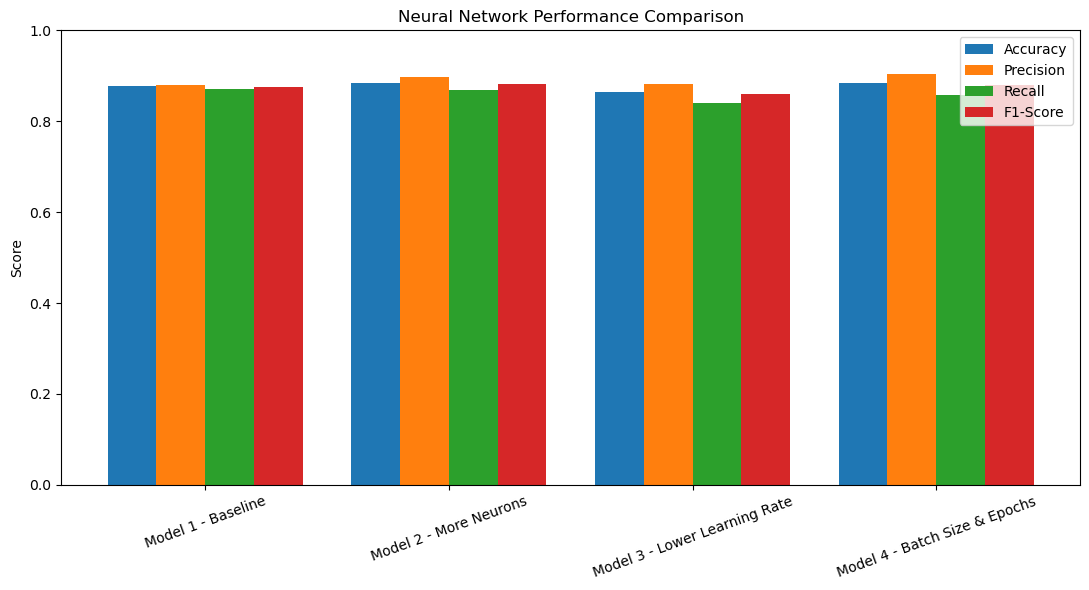

In [40]:
plt.figure(figsize=(11,6))
x=np.arange(len(final_results)); width=.2
for offset, metric in zip([-1.5,-.5,.5,1.5], ["Accuracy","Precision","Recall","F1-Score"]):
    plt.bar(x+offset*width, final_results[metric], width, label=metric)
plt.xticks(x, final_results["Model"], rotation=20); plt.ylabel("Score"); plt.ylim(0,1)
plt.title("Neural Network Performance Comparison"); plt.legend(); plt.tight_layout(); plt.show()

### 6. Results and Analysis

- **Model 1:** 87.44% accuracy, 89.36% precision, 84.96% recall and 87.11% F1-score.
- **Model 2:** 88.75% accuracy, 90.94% precision, 86.05% recall and 88.43% F1-score.
- **Model 3:** 86.08% accuracy, 87.64% precision, 83.96% recall and 85.76% F1-score.
- **Model 4:** 88.86% accuracy, 90.48% precision, 86.83% recall and 88.62% F1-score.

Increasing the hidden-layer size improved performance from Model 1 to Model 2, suggesting that the larger network could represent the patterns in the 12 input features more effectively. Model 3 used a smaller learning rate of 0.0001 and performed worse under the same 20-epoch training budget, so the lower learning rate was not beneficial in this experiment. Model 4 used the stronger 64/32 architecture, batch size 64 and 30 epochs. It achieved the highest recorded accuracy, recall and F1-score, while Model 2 had slightly higher precision.

**Final model:** Model 4 is selected because phishing detection should pay particular attention to recall and F1-score: missing a phishing URL is more serious than simply maximizing overall accuracy.

## 7. Final Model Evaluation

In [41]:
final_prediction = prediction_4
final_probability = probability_4.ravel()

print("Final Model Performance")
print("Accuracy :", accuracy_score(y_test, final_prediction))
print("Precision:", precision_score(y_test, final_prediction))
print("Recall   :", recall_score(y_test, final_prediction))
print("F1-Score :", f1_score(y_test, final_prediction))

cm = confusion_matrix(y_test, final_prediction)
print("\nConfusion Matrix:")
print(cm)

Final Model Performance
Accuracy : 0.883177813689204
Precision: 0.9031195079086116
Recall   : 0.8581567686045298
F1-Score : 0.88006422263848

Confusion Matrix:
[[8720  882]
 [1359 8222]]


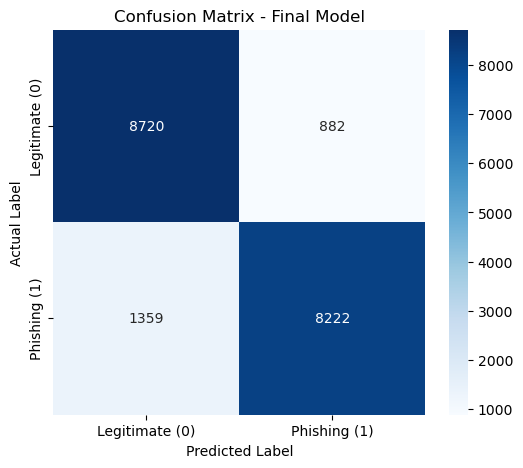

              precision    recall  f1-score   support

  Legitimate       0.87      0.91      0.89      9602
    Phishing       0.90      0.86      0.88      9581

    accuracy                           0.88     19183
   macro avg       0.88      0.88      0.88     19183
weighted avg       0.88      0.88      0.88     19183



In [42]:
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Legitimate (0)","Phishing (1)"],
            yticklabels=["Legitimate (0)","Phishing (1)"])
plt.title("Confusion Matrix - Final Model"); plt.xlabel("Predicted Label"); plt.ylabel("Actual Label"); plt.show()

print(classification_report(y_test, final_prediction, target_names=["Legitimate","Phishing"]))

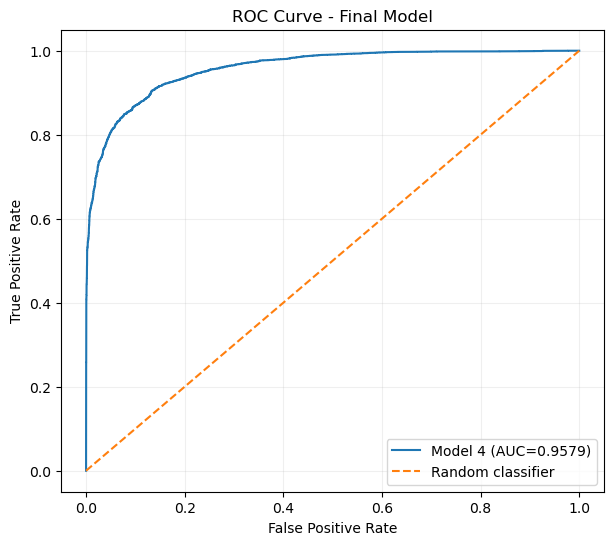

ROC-AUC: 0.9579171764762765


In [43]:
# Optional final diagnostic: ROC-AUC
from sklearn.metrics import roc_curve, roc_auc_score
fpr, tpr, _ = roc_curve(y_test, final_probability)
auc_score = roc_auc_score(y_test, final_probability)
plt.figure(figsize=(7,6)); plt.plot(fpr,tpr,label=f"Model 4 (AUC={auc_score:.4f})")
plt.plot([0,1],[0,1],linestyle="--",label="Random classifier")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title("ROC Curve - Final Model"); plt.legend(); plt.grid(alpha=.2); plt.show()
print("ROC-AUC:", auc_score)

In [44]:
sample = pd.DataFrame({
    "Phishing probability": final_probability[:10].round(3),
    "Model says": ["Phishing" if p == 1 else "Legitimate" for p in final_prediction[:10]],
    "Actual": ["Phishing" if a == 1 else "Legitimate" for a in y_test.values[:10]],
})
sample["Correct?"] = sample["Model says"] == sample["Actual"]
print(sample)

   Phishing probability  Model says      Actual  Correct?
0                 0.257  Legitimate  Legitimate      True
1                 0.172  Legitimate  Legitimate      True
2                 1.000    Phishing    Phishing      True
3                 0.970    Phishing    Phishing      True
4                 0.011  Legitimate  Legitimate      True
5                 0.225  Legitimate    Phishing     False
6                 0.731    Phishing  Legitimate     False
7                 0.138  Legitimate  Legitimate      True
8                 0.040  Legitimate  Legitimate      True
9                 0.412  Legitimate  Legitimate      True


In [ ]:
def check_url(i):
    idx = y_test.index[i]                     
    prob = float(model_4.predict(X_test[i:i+1], verbose=0)[0][0])
    print("URL        :", df.loc[idx, "domain"])
    print("Phishing probability:", round(prob, 3))
    print("Model says :", "PHISHING" if prob >= 0.5 else "LEGITIMATE")
    print("Actual     :", "PHISHING" if y_test.iloc[i] == 1 else "LEGITIMATE")

check_url(9)      # change the number to test another URL

URL        : jsmagic.net/easter/
Phishing probability: 0.412
Model says : LEGITIMATE
Actual     : LEGITIMATE
